# Online Auctions: Exploratory Data Analysis

This notebook explores the Online Auctions dataset (eBay auctions for 3 products). The goal is to understand how an online auction market works before we use it for BidNow.

**Questions we want to answer**

1. Is the data clean?
2. How are items and auction types distributed?
3. What does the final price look like and does it differ a lot between items?
4. Does the opening bid change the price or the number of bidders?
5. Does a longer auction give a higher price or more bidders?
6. When do bids arrive and where is the price decided?
7. How competitive are the auctions?
8. Who are the bidders and does experience help to win?

We go from simple checks to more detailed questions. After each part we write what we learned.

In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
import missingno as msno
from scipy.stats import skew

In [2]:
DATA_PATH = '../data/auction.csv'

try:
    # Loading the dataset
    df = pd.read_csv(DATA_PATH)

    print("Dataset loaded successfully")
    print(f"Dataset has {df.shape[0]} rows and {df.shape[1]} columns")

except FileNotFoundError as e:
    print(f"Error: Could not find the dataset file: {e.filename}")

except Exception as e:
    print(f"An unexpected error occurred: {e}")

Dataset loaded successfully
Dataset has 10681 rows and 9 columns


In [3]:
df.head()

,auctionid,bid,bidtime,bidder,bidderrate,openbid,price,item,auction_type
0,1638893549,175.0,2.230949,schadenfreud,0.0,99.0,177.5,Cartier wristwatch,3 day auction
1,1638893549,100.0,2.600116,chuik,0.0,99.0,177.5,Cartier wristwatch,3 day auction
2,1638893549,120.0,2.600810,kiwisstuff,2.0,99.0,177.5,Cartier wristwatch,3 day auction
3,1638893549,150.0,2.601076,kiwisstuff,2.0,99.0,177.5,Cartier wristwatch,3 day auction
4,1638893549,177.5,2.909826,eli.flint@flightsafety.co,4.0,99.0,177.5,Cartier wristwatch,3 day auction


**Column meaning**

- `auctionid`: id of the auction (a label and not a number to calculate with, drop later)
- `bid`: amount of this bid
- `bidtime`: time of the bid in days since the auction started
- `bidder`: username of the bidder
- `bidderrate`: feedback rating of the bidder or a sign of experience
- `openbid`: opening bid set by the seller
- `price`: final price of the auction
- `item`: product sold
- `auction_type`: length of the auction (3 or 5 or 7 days)

In [4]:
# We leave out auctionid because it is only a label
numeric_cols = ["bid", "bidtime", "bidderrate", "openbid", "price"]
df[numeric_cols].describe()

,bid,bidtime,bidderrate,openbid,price
count,10681.000000,10681.000000,10670.000000,10681.000000,10681.000000
mean,207.586109,3.979628,31.936739,52.246256,335.043589
std,323.037396,2.353386,120.594074,168.453245,433.566009
min,0.010000,0.000567,-4.000000,0.010000,26.000000
25%,72.000000,1.949931,1.000000,1.000000,186.510000
50%,140.000000,4.140833,5.000000,4.990000,228.490000
75%,210.000000,6.448060,21.000000,50.000000,255.000000
max,5400.000000,6.999990,3140.000000,5000.000000,5400.000000


In [5]:
# Statistics summary for categorical columns
df.select_dtypes(exclude='number').describe()

,bidder,item,auction_type
count,10665,10681,10681
unique,3387,3,3
top,warrencheryl,Palm Pilot M515 PDA,7 day auction
freq,45,5917,7041


In [ ]:
# Simple ANSI design codes used to format printed headers
class Style:
    GREEN = '\033[32m'
    BOLD = '\033[1m'
    END = '\033[0m'

# Prints a centered and colored header
def print_header(title, width=90):
    border = '*' * width
    title = f"*{title.center(width - 2)}*"
    print(f"{Style.GREEN}{Style.BOLD}{border}")
    print(title)
    print(f"{border}{Style.END}")

# Fixed color palettes
TYPE_COLORS = {'3 day auction': '#DFB8F1', '5 day auction': '#9fc3fc', '7 day auction': '#C7E971'}
ITEM_COLORS = {'Cartier wristwatch': '#DFB8F1', 'Palm Pilot M515 PDA': '#9fc3fc', 'Xbox game console': '#C7E971'}

In [7]:
print_header("DATASET INFO", 60)
print(df.info())

************************************************************
*                       DATASET INFO                       *
************************************************************
<class 'pandas.DataFrame'>
RangeIndex: 10681 entries, 0 to 10680
Data columns (total 9 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   auctionid     10681 non-null  int64  
 1   bid           10681 non-null  float64
 2   bidtime       10681 non-null  float64
 3   bidder        10665 non-null  str    
 4   bidderrate    10670 non-null  float64
 5   openbid       10681 non-null  float64
 6   price         10681 non-null  float64
 7   item          10681 non-null  str    
 8   auction_type  10681 non-null  str    
dtypes: float64(5), int64(1), str(3)
memory usage: 751.1 KB
None


**First impressions**

- The average `bid` is much lower than the average `price` which is expected behavior.
- `bidderrate` can be negative. On eBay the feedback score is a net score so a negative value is possible.
- `bid`, `openbid` and `price` have a very big range. This is because three different products are mixed in one column. We will always compare inside one item.

## Missing Values

In [8]:
print_header("DATASET MISSING VALUES", 60)
missing = df.isna().sum().to_frame('missing')
missing['percent'] = (missing['missing'] / len(df) * 100).round(3)
missing

************************************************************
*                  DATASET MISSING VALUES                  *
************************************************************


,missing,percent
auctionid,0,0.000
bid,0,0.000
bidtime,0,0.000
bidder,16,0.150
bidderrate,11,0.103
openbid,0,0.000
price,0,0.000
item,0,0.000
auction_type,0,0.000


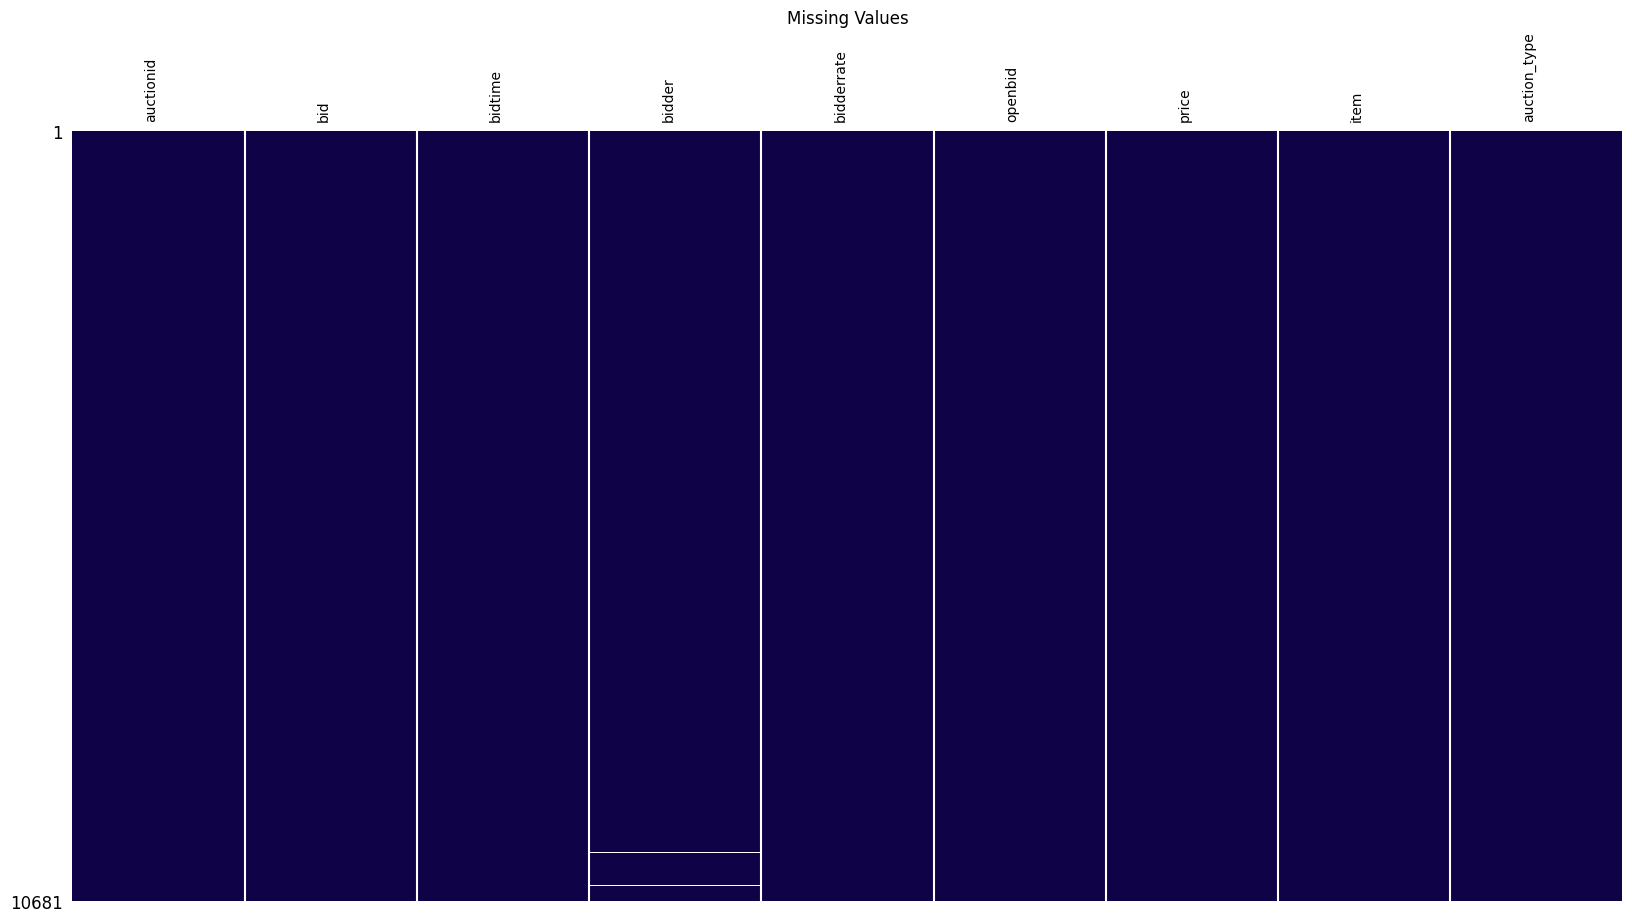

In [9]:
fig, ax = plt.subplots(figsize=(20, 10))

# sparkline=False silences a warning, since it can't render on a shared axis anyway
msno.matrix(df, color=(16/255, 2/255, 71/255), ax=ax, fontsize=10, sparkline=False)
ax.set_title("Missing Values", fontsize=12)
ax.set_xticklabels(ax.get_xticklabels(), rotation=90, ha='right')

plt.show()

In [10]:
# Are the missing values clustered in particular auctions or items?
rows_with_missing = df[df.isna().any(axis=1)]
print(f"Rows with at least one missing value: {len(rows_with_missing)} ({len(rows_with_missing) / len(df) * 100:.2f}%)")
print(f"Auctions affected: {rows_with_missing['auctionid'].nunique()} of {df['auctionid'].nunique()}")
print()
print("Items of the affected rows:")
print(rows_with_missing['item'].value_counts())
print()

# Are bidder and bidderrate missing on the same rows?
missing_df = df[['bidder', 'bidderrate']].isna()
print(pd.crosstab(missing_df['bidder'], missing_df['bidderrate'], rownames=['Missing Bidder'], colnames=['Missing BidderRate']))

Rows with at least one missing value: 27 (0.25%)
Auctions affected: 6 of 628

Items of the affected rows:
item
Xbox game console    27
Name: count, dtype: int64

Missing BidderRate  False  True 
Missing Bidder                  
False               10654     11
True                   16      0


#### Conclusion

Only a very small part of the data has missing values. `bidder` is missing in 16 rows and `bidderrate` in 11 rows. Together this is 27 rows (0.25% of 10,681).
All 27 rows belong to the Xbox item and sit in only 6 of 628 auctions. `bidder` and `bidderrate` are never missing on the same row. This looks like a problem of a few auctions and not of the whole data.
We do not need to fill or delete these rows. All price and auction questions use other columns. Only the bidder analysis uses `bidder` and `bidderrate` and it can skip the missing rows.

In [11]:
def unique_and_missing_values(cols):
    # For each column, print its distinct values, their counts and how many entries are missing
    for col in cols:
        unique_qnt = df[col].nunique()
        missing_qnt = df[col].isna().sum()
        counts = df[col].value_counts(dropna=True) # excludes NaN from the counted values

        max_len = max(len(str(v)) for v in counts.index)

        print(f'{Style.GREEN}{Style.BOLD}{col}{Style.END}')
        print(f'Number of distinct values: {unique_qnt}')
        print(f'Missing quantity: {missing_qnt}')
        print()
        for v, c in counts.items():
            print(f'-> {str(v):<{max_len}} | {c}')
        print()

unique_and_missing_values(['item', 'auction_type'])

item
Number of distinct values: 3
Missing quantity: 0

-> Palm Pilot M515 PDA | 5917
-> Xbox game console   | 2811
-> Cartier wristwatch  | 1953

auction_type
Number of distinct values: 3
Missing quantity: 0

-> 7 day auction | 7041
-> 3 day auction | 2023
-> 5 day auction | 1617



## Unique Values per Column

In [12]:
cols = list(df.columns)
max_len = max(len(col) for col in cols)

print('Number of unique values per column')
for col in cols:
    print(f'{col:<{max_len}}  {df[col].nunique()}')

Number of unique values per column
auctionid     628
bid           1858
bidtime       10400
bidder        3387
bidderrate    301
openbid       109
price         318
item          3
auction_type  3


## Duplicate Rows

In [13]:
print(f"Exact duplicate rows: {df.duplicated().sum()}")

# The same bidder bidding the same amount at the same time in the same auction should not happen
key = ['auctionid', 'bidder', 'bid', 'bidtime']
print(f"Duplicates on {key}: {df.duplicated(subset=key).sum()}")

Exact duplicate rows: 0
Duplicates on ['auctionid', 'bidder', 'bid', 'bidtime']: 0


### Conclusion

There are no duplicates. One bidder placing many different bids in the same auction is normal so we do not treat that as a duplicate.

In [14]:
# Number of distinct values of each auction-level attribute within an auction (should all be 1)
auction_level_cols = ['openbid', 'price', 'item', 'auction_type']
consistency = df.groupby('auctionid')[auction_level_cols].nunique()

print_header("AUCTIONS WITH INCONSISTENT ATTRIBUTES", 60)
for col in auction_level_cols:
    print(f"{col:<14} {(consistency[col] > 1).sum()} auctions with more than one value")

************************************************************
*          AUCTIONS WITH INCONSISTENT ATTRIBUTES           *
************************************************************
openbid        1 auctions with more than one value
price          0 auctions with more than one value
item           0 auctions with more than one value
auction_type   0 auctions with more than one value


In [15]:
inconsistent_auction_id = consistency[consistency['openbid'] > 1].index

print(f"Inconsistent auction ID: {inconsistent_auction_id}")

display(df[df['auctionid'].isin(inconsistent_auction_id)])

Inconsistent auction ID: Index([3019271858], dtype='int64', name='auctionid')


,auctionid,bid,bidtime,bidder,bidderrate,openbid,price,item,auction_type
5508,3019271858,50.69,0.08971,ladybugdazzle,416.0,0.01,245.0,Palm Pilot M515 PDA,7 day auction
5509,3019271858,20.00,0.12251,crosswise_69,7.0,1.00,245.0,Palm Pilot M515 PDA,7 day auction
5510,3019271858,25.00,0.12266,crosswise_69,7.0,0.01,245.0,Palm Pilot M515 PDA,7 day auction
5511,3019271858,100.00,0.65247,bouwkne@knmg.nl,7.0,0.01,245.0,Palm Pilot M515 PDA,7 day auction
5512,3019271858,100.00,4.43080,11860256,40.0,0.01,245.0,Palm Pilot M515 PDA,7 day auction
5513,3019271858,149.95,5.92094,barnabusinfla,13.0,0.01,245.0,Palm Pilot M515 PDA,7 day auction
5514,3019271858,105.00,5.96632,jdowdlee,6.0,0.01,245.0,Palm Pilot M515 PDA,7 day auction
5515,3019271858,110.00,5.97692,lexybean,193.0,0.01,245.0,Palm Pilot M515 PDA,7 day auction
5516,3019271858,175.00,6.25448,babatso,79.0,0.01,245.0,Palm Pilot M515 PDA,7 day auction
5517,3019271858,155.00,6.42084,smellthatcigar,40.0,0.01,245.0,Palm Pilot M515 PDA,7 day auction


### Conclusion

Only one auction has a changing opening bid and the difference comes from a single row (a typing error is likely). For this auction we use the most common value (the mode) as the opening bid. The other attributes are always consistent.

### Logic checks

Here we look for values that should not exist.

In [16]:
df['duration'] = df['auction_type'].str.extract(r'(\d+)').astype(float)   # '7 day auction' -> 7

print_header("LOGIC CHECKS", 60)
print(f"Negative bid times:                     {(df['bidtime'] < 0).sum()}")
print(f"Bids after the end of the auction:      {(df['bidtime'] > df['duration']).sum()}")
print(f"Bids lower than the opening bid:        {(df['bid'] < df['openbid']).sum()}")
print(f"Bids equal to or below zero:            {(df['bid'] <= 0).sum()}")
print(f"Auctions with price lower than openbid: {(df.groupby('auctionid')['price'].first() < df.groupby('auctionid')['openbid'].agg(lambda s: s.mode().iloc[0])).sum()}")
print(f"Rows with a negative bidder rating:     {(df['bidderrate'] < 0).sum()}")

************************************************************
*                       LOGIC CHECKS                       *
************************************************************
Negative bid times:                     0
Bids after the end of the auction:      0
Bids lower than the opening bid:        2
Bids equal to or below zero:            0
Auctions with price lower than openbid: 0
Rows with a negative bidder rating:     27


In [17]:
# Look at the bids that are lower than the opening bid
display(df[df['bid'] < df['openbid']][['auctionid', 'bid', 'bidtime', 'bidder', 'openbid', 'price', 'item']])

,auctionid,bid,bidtime,bidder,openbid,price,item
3202,3013951754,130.0,3.95325,bakheet,140.0,242.5,Palm Pilot M515 PDA
3203,3013951754,135.0,4.07134,ansonnowka,140.0,242.5,Palm Pilot M515 PDA


### Conclusion

All bid times are inside the auction. Only 2 bids are lower than the opening bid and both belong to one Palm Pilot auction (3013951754). This is a data error and we ignore them. 27 rows have a negative bidder rating (the lowest is -4). This is possible on eBay and is not an error but we must remember it when we use a log scale.

### What is one row?

The data is stored per bid. A busy auction has many rows and a quiet one only a few. If we calculate averages on the bid table every busy auction counts more. For market questions the right unit is the auction.

In [18]:
bids_per_auction = df.groupby('auctionid').size()

print(f"Total bids:     {len(df)}")
print(f"Total auctions: {df['auctionid'].nunique()}")
print()
print(bids_per_auction.describe())

Total bids:     10681
Total auctions: 628

count    628.000000
mean      17.007962
std       10.885877
min        1.000000
25%        8.000000
50%       16.000000
75%       24.000000
max       75.000000
dtype: float64


## Building the auction-level table

We make one row per auction. Besides the original columns we add features that we will use later:

- `n_bids` and `n_bidders`: how much activity the auction had
- `max_bid`: highest bid in the data
- `first_bid_time` and `last_bid_time`: when the bidding started and ended
- `winner` and `winner_rate`: the bidder with the highest bid and his rating (the winner is our best guess)
- `win_time_frac`: when the winning bid was placed as a share of the auction length
- `price_rel`: price divided by the median price of the same item (this makes items comparable)
- `openbid_ratio`: opening bid divided by the median price of the same item
- `premium`: final price divided by the opening bid

In [19]:
df['time_frac'] = df['bidtime'] / df['duration']   # 0 = start of the auction, 1 = end

# The winner is the bidder of the highest bid (the latest one if two bids are equal)
winning_rows = (df.sort_values(['auctionid', 'bid', 'bidtime'])
                  .groupby('auctionid').tail(1)
                  .set_index('auctionid'))

auctions = df.groupby('auctionid').agg(
    item=('item', 'first'),
    auction_type=('auction_type', 'first'),
    duration=('duration', 'first'),
    openbid=('openbid', lambda s: s.mode().iloc[0]), # fixes the one inconsistent auction
    price=('price', 'first'),
    n_bids=('bid', 'size'),
    n_bidders=('bidder', 'nunique'),
    max_bid=('bid', 'max'),
    first_bid_time=('bidtime', 'min'),
    last_bid_time=('bidtime', 'max'),
    mean_rate=('bidderrate', 'mean'),
    median_rate=('bidderrate', 'median')
).reset_index()

# Adding the winner information
auctions = auctions.join(winning_rows[['bidder', 'bidderrate', 'time_frac']].rename(columns={'bidder': 'winner', 'bidderrate': 'winner_rate', 'time_frac': 'win_time_frac'}), on='auctionid')

# Features that compare auctions of the same item
item_median_price = auctions.groupby('item')['price'].transform('median')
auctions['price_rel'] = auctions['price'] / item_median_price
auctions['openbid_ratio'] = auctions['openbid'] / item_median_price
auctions['premium'] = auctions['price'] / auctions['openbid']

print(f"Auction-level table -> {auctions.shape[0]} rows and {auctions.shape[1]} columns")
auctions.head()

Auction-level table -> 628 rows and 19 columns


,auctionid,item,auction_type,duration,openbid,price,n_bids,n_bidders,max_bid,first_bid_time,last_bid_time,mean_rate,median_rate,winner,winner_rate,win_time_frac,price_rel,openbid_ratio,premium
0,1638843936,Cartier wristwatch,7 day auction,7.0,500.0,1625.0,7,5,1625.0,0.478368,6.893113,38.428571,6.0,carloss8055,5.0,0.984730,3.186275,0.980392,3.250000
1,1638844284,Cartier wristwatch,7 day auction,7.0,200.0,500.0,2,2,500.0,1.237419,1.252407,16.500000,16.5,njbirdmom,33.0,0.178915,0.980392,0.392157,2.500000
2,1638844464,Cartier wristwatch,7 day auction,7.0,300.0,740.0,16,5,740.0,1.811134,6.999745,9.125000,5.0,adammurry,5.0,0.999964,1.450980,0.588235,2.466667
3,1638844729,Cartier wristwatch,7 day auction,7.0,225.0,320.0,11,2,320.0,6.121782,6.999213,29.636364,18.0,sylvesterii,82.0,0.999888,0.627451,0.441176,1.422222
4,1638893549,Cartier wristwatch,3 day auction,3.0,99.0,177.5,5,4,177.5,2.230949,2.909826,1.600000,2.0,eli.flint@flightsafety.co,4.0,0.969942,0.348039,0.194118,1.792929


## Market overview: items and auction types

First we look at what is in the data. We compare the share of **bids** with the share of **auctions**. They can be very different because some auctions have many more bids than others.

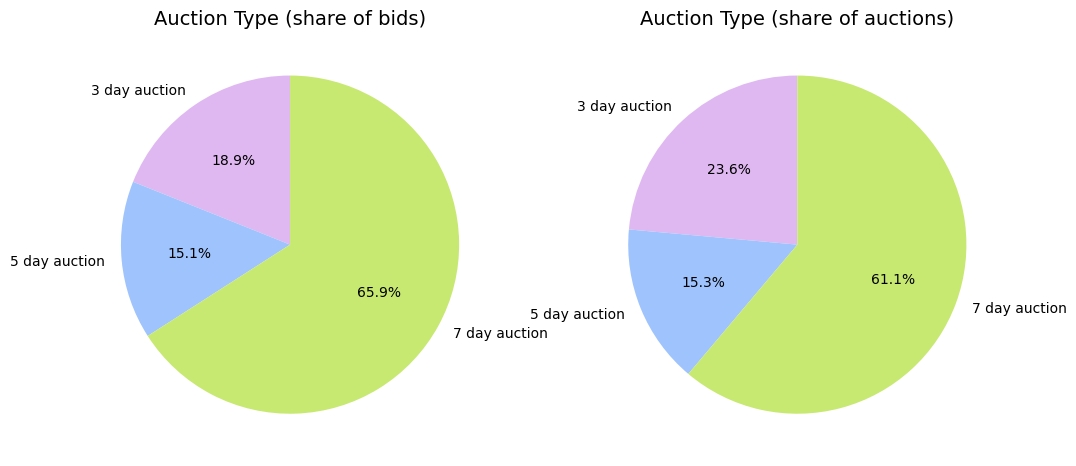

In [20]:
# Auction type by bids and by auctions
type_bids = df['auction_type'].value_counts().sort_index()
type_auctions = auctions['auction_type'].value_counts().sort_index()

fig, axes = plt.subplots(1, 2, figsize=(12, 6))
axes[0].pie(type_bids, labels=type_bids.index, autopct='%1.1f%%', startangle=90, colors=[TYPE_COLORS[t] for t in type_bids.index])
axes[0].set_title('Auction Type (share of bids)', fontsize=14)

axes[1].pie(type_auctions, labels=type_auctions.index, autopct='%1.1f%%', startangle=90, colors=[TYPE_COLORS[t] for t in type_auctions.index])
axes[1].set_title('Auction Type (share of auctions)', fontsize=14)

plt.show()

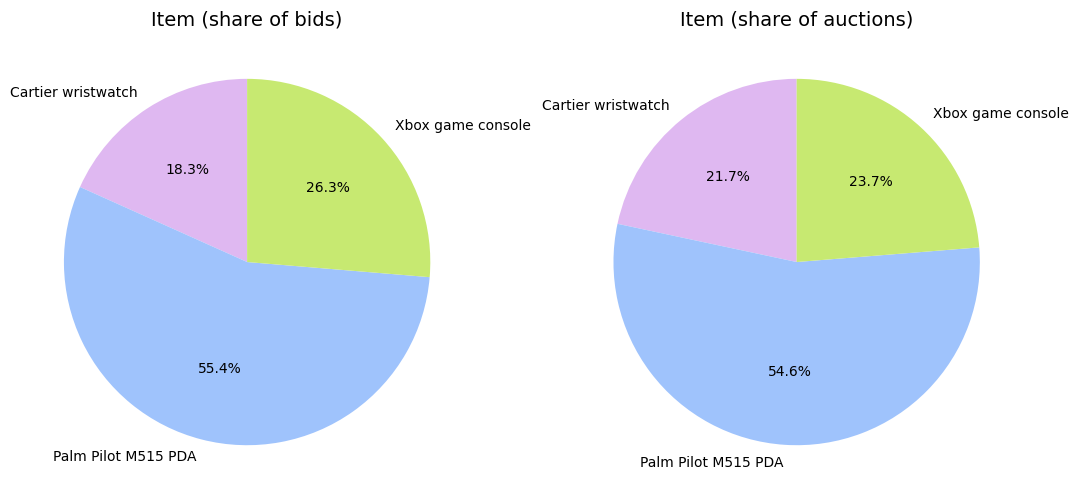

In [21]:
# Item by bids and by auctions
item_bids = df['item'].value_counts().sort_index()
item_auctions = auctions['item'].value_counts().sort_index()

fig, axes = plt.subplots(1, 2, figsize=(13, 6))
axes[0].pie(item_bids, labels=item_bids.index, autopct='%1.1f%%', startangle=90, colors=['#DFB8F1', '#9fc3fc', '#C7E971'])
axes[0].set_title('Item (share of bids)', fontsize=14)

axes[1].pie(item_auctions, labels=item_auctions.index, autopct='%1.1f%%', startangle=90, colors=['#DFB8F1', '#9fc3fc', '#C7E971'])
axes[1].set_title('Item (share of auctions)', fontsize=14)

plt.show()

auction_type,3 day auction,5 day auction,7 day auction,All
item,,,,
Cartier wristwatch,18,21,97,136
Palm Pilot M515 PDA,95,54,194,343
Xbox game console,35,21,93,149
All,148,96,384,628


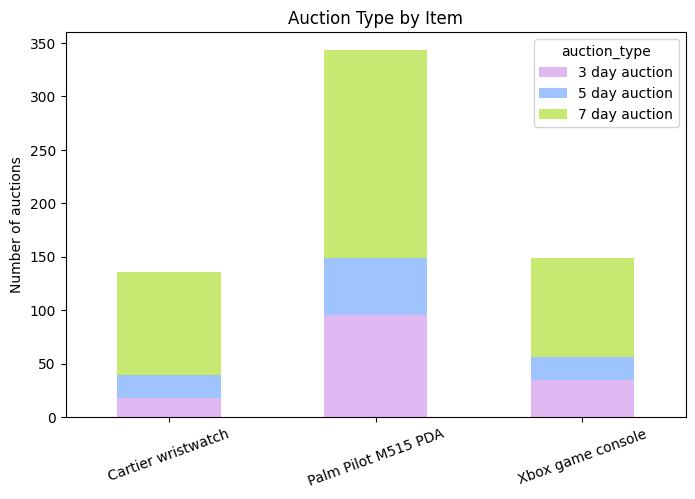

In [22]:
# Do all items have all auction types? Small cells give weak results later
counts = pd.crosstab(auctions['item'], auctions['auction_type'], margins=True)
display(counts)

pd.crosstab(auctions['item'], auctions['auction_type']).plot(kind='bar', stacked=True, figsize=(8, 5), color=[TYPE_COLORS[c] for c in sorted(TYPE_COLORS)])
plt.title('Auction Type by Item')
plt.xlabel('')
plt.ylabel('Number of auctions')
plt.xticks(rotation=20)
plt.show()

### Conclusion

- The Palm Pilot has the most auctions and the Cartier watch has the fewest. The share of bids is different from the share of auctions for some items. This means that auctions of some items attract more bids than others.
- The 7 day auction is by far the most common type. Some item and type groups are very small (for example Cartier 3 day and 5 day). Any comparison of those groups is weak and we must be careful.
- Because the groups are not equal, a simple comparison of auction types can be misleading. A type may look better only because it has more of an expensive item.

## Auction length

auctions  median_price  avg_bids  \
item                auction_type                                      
Cartier wristwatch  3 day auction        18         380.0     13.89   
                    5 day auction        21         560.0     16.90   
                    7 day auction        97         540.0     13.90   
Palm Pilot M515 PDA 3 day auction        95         220.0     12.80   
                    5 day auction        54         232.5     16.09   
                    7 day auction       194         232.5     19.75   
Xbox game console   3 day auction        35         122.5     15.91   
                    5 day auction        21         122.5     18.71   
                    7 day auction        93         125.0     20.01   

                                   avg_bidders  
item                auction_type                
Cartier wristwatch  3 day auction         5.33  
                    5 day auction         7.57  
                    7 day auction         6.88  
Palm Pilot M515 PDA 3 day auction         6.91  
                    5 day auction         7.67  
                    7 day auction        10.06  
Xbox game console   3 day auction         7.57  
                    5 day auction         7.81  
                    7 day auction         8.60

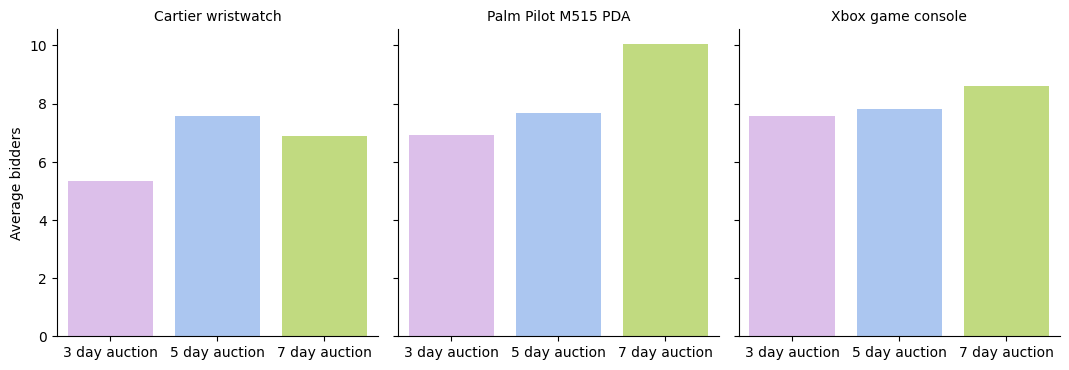

In [23]:
order = sorted(TYPE_COLORS)

by_item_type = auctions.groupby(['item', 'auction_type']).agg(
    auctions=('auctionid', 'size'),
    median_price=('price', 'median'),
    avg_bids=('n_bids', 'mean'),
    avg_bidders=('n_bidders', 'mean'),).round(2)

display(by_item_type)


g = sns.catplot(data=auctions, x='auction_type', y='n_bidders', col='item', hue='auction_type', order=order,
                palette=TYPE_COLORS, kind='bar', errorbar=None, height=4, aspect=0.9, sharey=True)
g.set_titles('{col_name}')
g.set_axis_labels('', 'Average bidders')
plt.show()

### Conclusion

- Palm Pilot and Xbox show the same pattern. A longer auction has more bids (Palm Pilot 12.8 → 16.1 → 19.8 and Xbox 15.9 → 18.7 → 20.0). It also has more bidders. The median price stays almost the same (Palm Pilot 220 → 232.5 → 232.5 and Xbox 122.5 → 122.5 → 125).
- So a longer auction attracts more people but does not give a clearly higher price for these two items.
- The Cartier watch has no clear pattern. The 3 day and 5 day groups have only 18 and 21 auctions so we should not trust them.
- The seller chooses the length. So this is an association and not a proof of cause.

## Competition

How many people fight for an item? More bidders should give a higher price. We check if this is true.

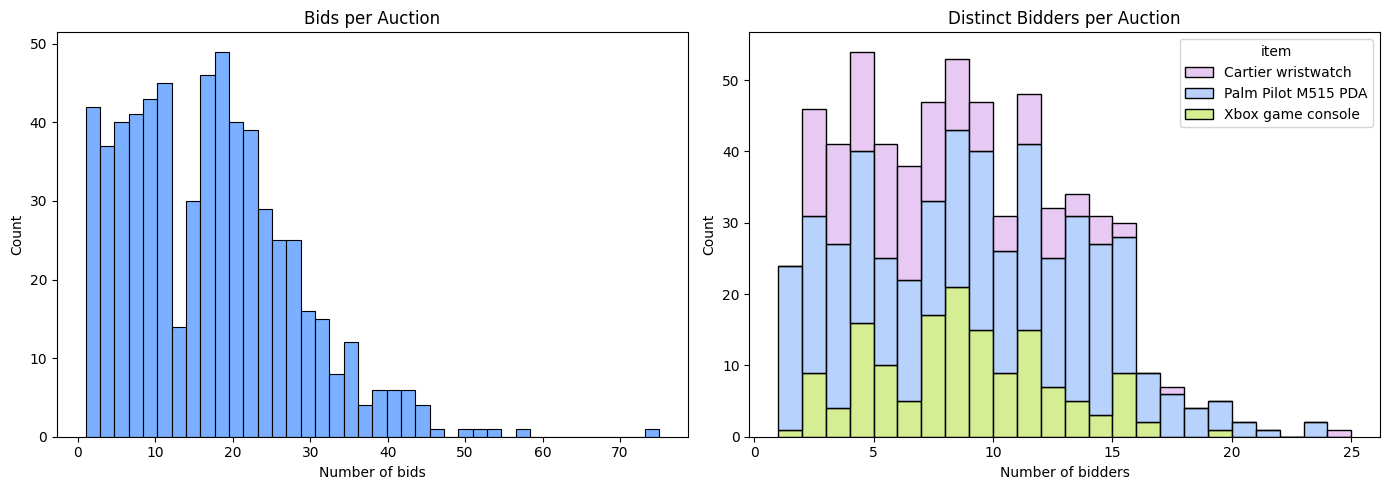

Auctions with a single bid:           21 (3.3%)
Auctions with a single bidder:        24 (3.8%)
Auctions with 2 bidders or fewer:     11.1%


In [24]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.histplot(data=auctions, x='n_bids', bins=40, color='#4D96FF', ax=axes[0])
axes[0].set_title('Bids per Auction')
axes[0].set_xlabel('Number of bids')

sns.histplot(data=auctions, x='n_bidders', hue='item', palette=ITEM_COLORS, multiple='stack', bins=range(1, int(auctions['n_bidders'].max()) + 2), ax=axes[1])
axes[1].set_title('Distinct Bidders per Auction')
axes[1].set_xlabel('Number of bidders')

plt.tight_layout()
plt.show()

print(f"Auctions with a single bid:           {(auctions['n_bids'] == 1).sum()} ({(auctions['n_bids'] == 1).mean() * 100:.1f}%)")
print(f"Auctions with a single bidder:        {(auctions['n_bidders'] == 1).sum()} ({(auctions['n_bidders'] == 1).mean() * 100:.1f}%)")
print(f"Auctions with 2 bidders or fewer:     {(auctions['n_bidders'] <= 2).mean() * 100:.1f}%")

### Conclusion

Most auctions have real competition. Only 3.8% have a single bidder and only 11.1% have 2 bidders or fewer. The number of bids per auction is very spread out (1 to 75). A few auctions have many more bids than the rest.

This part only shows the distribution. To know if more bidders give a higher price we still need a chart of `n_bidders` against `price_rel` for each item.